In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from src.data import PROCESSED
from src.eval import PREDS_DIR, ROOT
from src.dl_cache import RAW_FS, SEQ_FS
from src.dl_dataset import ApneaDataset, load_cache
from src.dl_models import ApneaSeqNet
from src.train_dl import CKPT_DIR

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
folds_df = pd.read_csv(PROCESSED / "folds.csv")
train_cache = load_cache(folds_df["record"].unique())

test_df = pd.read_csv(PROCESSED / "test_clean.csv")
test_cache = load_cache(test_df["record"].unique())



GPU: NVIDIA RTX A2000 8GB Laptop GPU


load_cache:   0%|          | 0/35 [00:00<?, ?npz/s]

load_cache:   0%|          | 0/35 [00:00<?, ?npz/s]

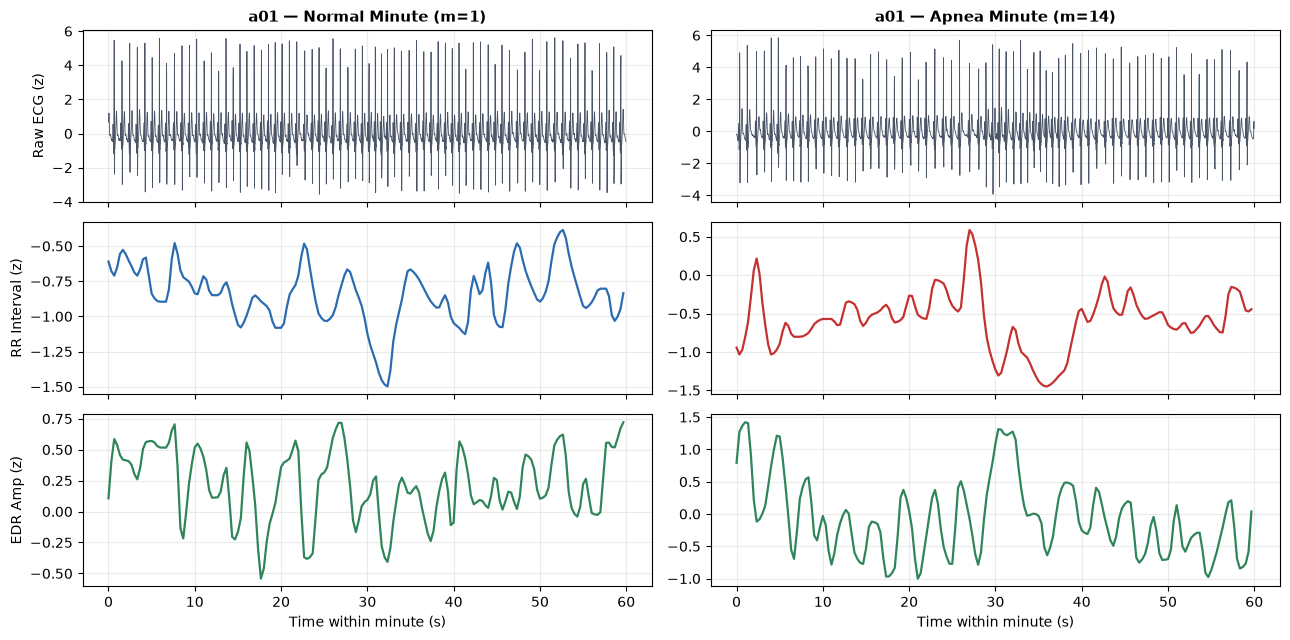

In [2]:
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def pick_clean_minute(df, rec, target_label):
    sub = df[df["record"] == rec].sort_values("minute").reset_index(drop=True)
    # Pick a minute whose immediate neighbors share the same label
    for i in range(1, len(sub) - 1):
        if sub.loc[i, "label"] == target_label and sub.loc[i-1, "label"] == target_label and sub.loc[i+1, "label"] == target_label:
            return int(sub.loc[i, "minute"])
    return int(sub[sub["label"] == target_label]["minute"].iloc[0])

rec = "a01"
m_norm = pick_clean_minute(folds_df, rec, 0)
m_apn  = pick_clean_minute(folds_df, rec, 1)

fig, axes = plt.subplots(3, 2, figsize=(13, 6.5), sharex=True)
t_raw = np.arange(60 * RAW_FS) / RAW_FS
t_seq = np.arange(60 * SEQ_FS) / SEQ_FS

for col, (m, title, color) in enumerate([
    (m_norm, f"{rec} — Normal Minute (m={m_norm})", "#2b6cb0"),
    (m_apn,  f"{rec} — Apnea Minute (m={m_apn})",   "#c53030"),
]):
    raw_seg = train_cache[rec]["raw_ecg"][0, m*60*RAW_FS : (m+1)*60*RAW_FS]
    rr_seg  = train_cache[rec]["rr_edr"][0,  m*60*SEQ_FS : (m+1)*60*SEQ_FS]
    edr_seg = train_cache[rec]["rr_edr"][1,  m*60*SEQ_FS : (m+1)*60*SEQ_FS]

    axes[0, col].plot(t_raw, raw_seg, lw=0.6, color="#4a5568")
    axes[0, col].set_title(title, fontsize=11, fontweight="bold")
    axes[1, col].plot(t_seq, rr_seg,  lw=1.6, color=color)
    axes[2, col].plot(t_seq, edr_seg, lw=1.6, color="#2f855a")
    axes[2, col].set_xlabel("Time within minute (s)")

axes[0, 0].set_ylabel("Raw ECG (z)")
axes[1, 0].set_ylabel("RR Interval (z)")
axes[2, 0].set_ylabel("EDR Amp (z)")

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(FIG / "fig_dl_signal_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

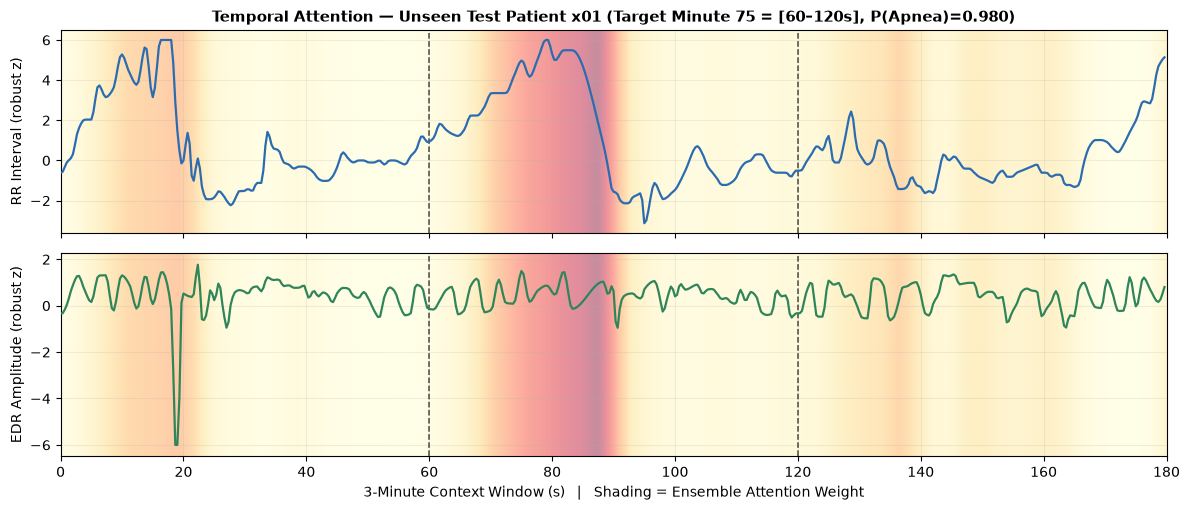

In [3]:
test_preds = pd.read_csv(PREDS_DIR / "test_cnn_bigru_rredr_3m.csv")
# Pick a confident true-positive apnea minute on an unseen test patient
cand = test_preds[(test_preds["label"] == 1) & (test_preds["y_prob"] >= 0.90)].iloc[10]
row_idx = cand.name
rec_ex, min_ex, prob_ex = cand["record"], int(cand["minute"]), float(cand["y_prob"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_ds = ApneaDataset(test_df, test_cache, mode="rr_edr", context_mins=3, augment=False)
x_ex, _ = test_ds[row_idx]
x_in = x_ex.unsqueeze(0).to(device)

attns = []
with torch.no_grad():
    for f in range(5):
        m = ApneaSeqNet(mode="rr_edr").to(device)
        m.load_state_dict(torch.load(CKPT_DIR / f"cnn_bigru_rredr_3m_patient_fold_f{f}.pt", map_location=device, weights_only=True))
        m.eval()
        _, w = m(x_in, return_attn=True)
        attns.append(w.squeeze(0).cpu().numpy())

attn_mean = np.mean(attns, axis=0)                          # shape: (67,)
t_win = np.arange(x_ex.shape[1]) / SEQ_FS                   # 0..180s
t_attn = np.linspace(0, 180, len(attn_mean))
attn_up = np.interp(t_win, t_attn, attn_mean)
attn_norm = (attn_up - attn_up.min()) / (attn_up.max() - attn_up.min() + 1e-8)

fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
for ax, sig, label, col in [
    (axes[0], x_ex[0].numpy(), "RR Interval (robust z)", "#2b6cb0"),
    (axes[1], x_ex[1].numpy(), "EDR Amplitude (robust z)", "#2f855a"),
]:
    ax.plot(t_win, sig, lw=1.6, color=col, zorder=3)
    ymin, ymax = sig.min() - 0.5, sig.max() + 0.5
    ax.imshow(
        attn_norm[None, :], aspect="auto", cmap="YlOrRd", alpha=0.45,
        extent=[0, 180, ymin, ymax], origin="lower", zorder=1
    )
    ax.axvline(60, ls="--", c="black", lw=1.1, alpha=0.7)
    ax.axvline(120, ls="--", c="black", lw=1.1, alpha=0.7)
    ax.set_ylim(ymin, ymax)
    ax.set_ylabel(label)
    ax.grid(alpha=0.2)

axes[0].set_title(
    f"Temporal Attention — Unseen Test Patient {rec_ex} (Target Minute {min_ex} = [60–120s], P(Apnea)={prob_ex:.3f})",
    fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("3-Minute Context Window (s)   |   Shading = Ensemble Attention Weight")
plt.tight_layout()
plt.savefig(FIG / "fig_dl_attention_overlay.png", dpi=200, bbox_inches="tight")
plt.show()

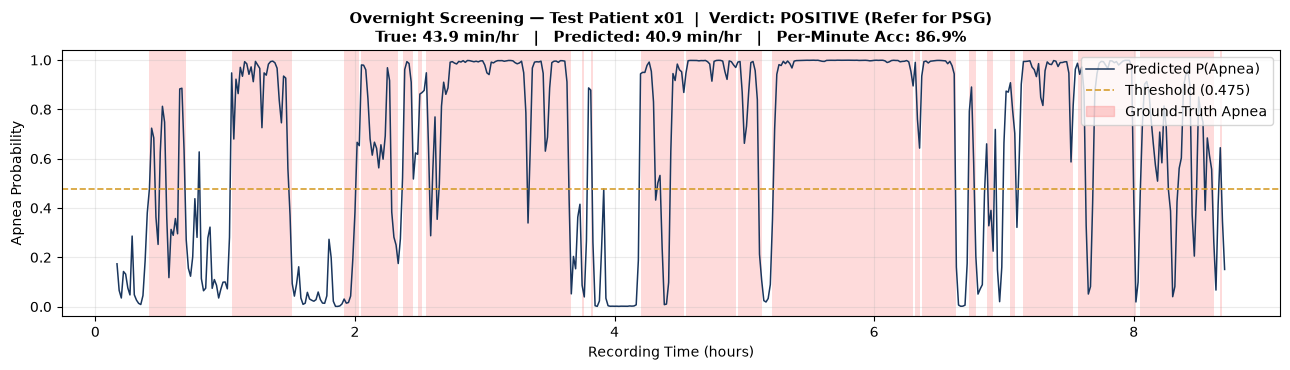

In [4]:
def plot_overnight_screening(rec: str, preds_df: pd.DataFrame, threshold: float = 0.475, save_path=None):
    sub = preds_df[preds_df["record"] == rec].sort_values("minute")
    hrs = sub["minute"].to_numpy() / 60.0
    y_true = sub["label"].to_numpy()
    y_prob = sub["y_prob"].to_numpy()
    y_pred = (y_prob >= threshold).astype(int)

    acc = accuracy_score(y_true, y_pred)
    true_mph = y_true.mean() * 60.0
    pred_mph = y_pred.mean() * 60.0
    verdict = "POSITIVE (Refer for PSG)" if pred_mph >= 5.0 else "NEGATIVE (Low Risk)"

    fig, ax = plt.subplots(figsize=(13, 3.8))
    for m in sub.loc[sub["label"] == 1, "minute"]:
        ax.axvspan(m / 60.0, (m + 1) / 60.0, color="#fc8181", alpha=0.28, lw=0)

    ax.plot(hrs, y_prob, lw=1.1, color="#1a365d", label="Predicted P(Apnea)")
    ax.axhline(threshold, ls="--", lw=1.2, color="#d69e2e", label=f"Threshold ({threshold:.3f})")
    ax.fill_between([], [], [], color="#fc8181", alpha=0.35, label="Ground-Truth Apnea")

    ax.set_ylim(-0.04, 1.04)
    ax.set_xlabel("Recording Time (hours)")
    ax.set_ylabel("Apnea Probability")
    ax.set_title(
        f"Overnight Screening — Test Patient {rec}  |  Verdict: {verdict}\n"
        f"True: {true_mph:.1f} min/hr   |   Predicted: {pred_mph:.1f} min/hr   |   Per-Minute Acc: {acc:.1%}",
        fontsize=11, fontweight="bold"
    )
    ax.legend(loc="upper right", frameon=True)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

# Pick an unseen test patient with mixed normal + apnea stretches
test_rec_rates = test_preds.groupby("record")["label"].mean()
demo_rec = test_rec_rates[(test_rec_rates > 0.25) & (test_rec_rates < 0.75)].index[0]
plot_overnight_screening(demo_rec, test_preds, threshold=0.475, save_path=FIG / "fig_dl_overnight_demo.png")